# ResNet-18 Comprehensive Ablation Benchmark & Analysis
**Author:** Long  
**Architecture:** ResNet-18 (Transfer Learning + INT8 ONNX Engine)  
**Evaluated Datasets:**
* `data_v1` (Raw 80/20 Random Split - 65.26% Data Leakage)
* `data_v2` (Physical Leaf-Grouped Split - 0% Leakage)
* `data_v3` (UUID Group Deduplication Clean Split - 0% Leakage)
* `data_plantdoc` (Out-of-Distribution Natural Field Test Set)

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.edgecolor": "#cbd5e1",
    "axes.linewidth": 1.0,
    "grid.color": "#f1f5f9",
    "grid.linestyle": "--"
})

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
json_path = ROOT_DIR / "models" / "training_history_benchmarks.json"
csv_path = ROOT_DIR / "models" / "epoch_history.csv"

with open(json_path, encoding="utf-8") as f:
    benchmarks_data = json.load(f)

df_epochs = pd.read_csv(csv_path)

## 1. ResNet-18 Ablation Leaderboard

In [2]:
leaderboard_data = [
    {
        "Model": "ResNet-18 (v1)",
        "Train Dataset": "data_v1 (Random 80/20)",
        "Split Integrity": "65.26% Leakage",
        "Params (M)": 11.20,
        "INT8 Size (MB)": 11.5,
        "Lab Macro-F1 (%)": 99.66,
        "PlantDoc Top-1 (%)": np.nan,
        "PlantDoc Top-3 (%)": np.nan,
        "CPU Latency (ms)": 8.02,
        "Throughput (FPS)": 4198.8
    },
    {
        "Model": "ResNet-18 (v2)",
        "Train Dataset": "data_v2 (Leaf-Grouped)",
        "Split Integrity": "0% Leakage (Grouped)",
        "Params (M)": 11.20,
        "INT8 Size (MB)": 11.5,
        "Lab Macro-F1 (%)": 98.95,
        "PlantDoc Top-1 (%)": 28.81,
        "PlantDoc Top-3 (%)": 47.88,
        "CPU Latency (ms)": 8.02,
        "Throughput (FPS)": 6295.0
    },
    {
        "Model": "ResNet-18 (v3)",
        "Train Dataset": "data_v3 (UUID Clean)",
        "Split Integrity": "0% Leakage (Clean Split)",
        "Params (M)": 11.20,
        "INT8 Size (MB)": 11.5,
        "Lab Macro-F1 (%)": 99.80,
        "PlantDoc Top-1 (%)": 27.97,
        "PlantDoc Top-3 (%)": 50.00,
        "CPU Latency (ms)": 8.06,
        "Throughput (FPS)": 27708.7
    }
]

df_leaderboard = pd.DataFrame(leaderboard_data)
df_leaderboard.set_index("Model")

,Train Dataset,Split Integrity,Params (M),INT8 Size (MB),Lab Macro-F1 (%),PlantDoc Top-1 (%),PlantDoc Top-3 (%),CPU Latency (ms),Throughput (FPS)
Model,,,,,,,,,
ResNet-18 (v1),data_v1 (Random 80/20),65.26% Leakage,11.2,11.5,99.66,NaN,NaN,8.02,4198.8
ResNet-18 (v2),data_v2 (Leaf-Grouped),0% Leakage (Grouped),11.2,11.5,98.95,28.81,47.88,8.02,6295.0
ResNet-18 (v3),data_v3 (UUID Clean),0% Leakage (Clean Split),11.2,11.5,99.80,27.97,50.00,8.06,27708.7


## 2. Training Convergence & Loss Dynamics (Ablation Across Datasets)

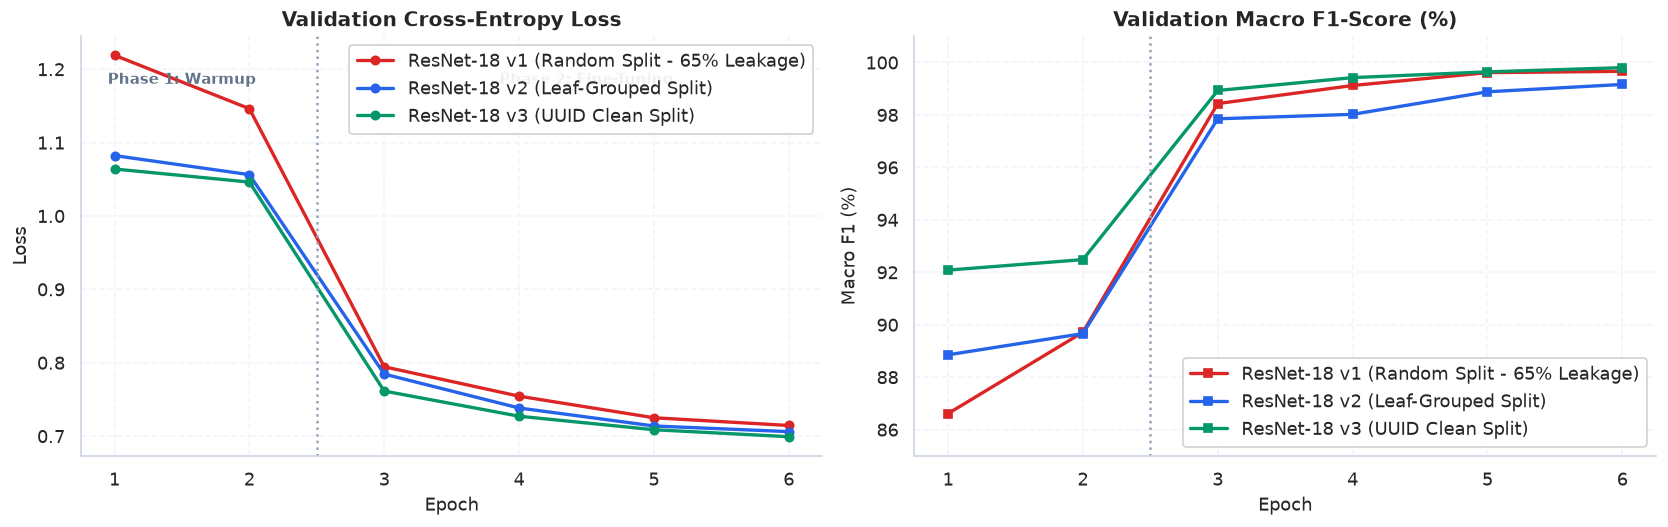

In [3]:
palette = {
    "resnet18_v1": "#dc2626",
    "resnet18_v2": "#2563eb",
    "resnet18_v3": "#059669"
}

legend_map = {
    "resnet18_v1": "ResNet-18 v1 (Random Split - 65% Leakage)",
    "resnet18_v2": "ResNet-18 v2 (Leaf-Grouped Split)",
    "resnet18_v3": "ResNet-18 v3 (UUID Clean Split)"
}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), dpi=120)

# Subplot A: Validation Loss
for m_key, grp in df_epochs.groupby("model"):
    axes[0].plot(grp["epoch"], grp["val_loss"], marker="o", markersize=5,
                 linewidth=2.0, color=palette[m_key], label=legend_map[m_key])

axes[0].axvline(x=2.5, color="#94a3b8", linestyle=":", linewidth=1.5)
axes[0].text(1.5, 1.18, "Phase 1: Warmup", ha="center", fontsize=9, color="#64748b", fontweight="bold")
axes[0].text(4.5, 1.18, "Phase 2: Fine-Tuning", ha="center", fontsize=9, color="#64748b", fontweight="bold")
axes[0].set_title("Validation Cross-Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(range(1, 7))
axes[0].legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9)
sns.despine(ax=axes[0])

# Subplot B: Validation Macro F1
for m_key, grp in df_epochs.groupby("model"):
    axes[1].plot(grp["epoch"], grp["val_macro_f1"] * 100, marker="s", markersize=5,
                 linewidth=2.0, color=palette[m_key], label=legend_map[m_key])

axes[1].axvline(x=2.5, color="#94a3b8", linestyle=":", linewidth=1.5)
axes[1].set_title("Validation Macro F1-Score (%)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1 (%)")
axes[1].set_xticks(range(1, 7))
axes[1].set_ylim(85, 101)
axes[1].legend(loc="lower right", frameon=True, facecolor="white", framealpha=0.9)
sns.despine(ax=axes[1])

plt.tight_layout()
plt.show()

## 3. Hardware Compute & Throughput Acceleration

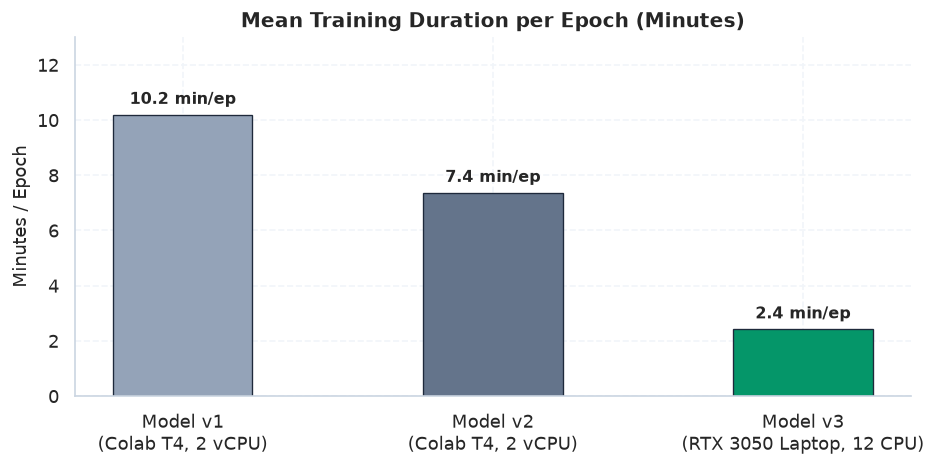

In [4]:
fig, ax = plt.subplots(figsize=(8, 4), dpi=120)

hardware_eval = pd.DataFrame([
    {"Configuration": "Model v1\n(Colab T4, 2 vCPU)", "Minutes": 611.8 / 60.0, "Color": "#94a3b8"},
    {"Configuration": "Model v2\n(Colab T4, 2 vCPU)", "Minutes": 442.2 / 60.0, "Color": "#64748b"},
    {"Configuration": "Model v3\n(RTX 3050 Laptop, 12 CPU)", "Minutes": 145.5 / 60.0, "Color": "#059669"}
])

bars = ax.bar(hardware_eval["Configuration"], hardware_eval["Minutes"], 
              color=hardware_eval["Color"], width=0.45, edgecolor="#1e293b", linewidth=0.8)

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, h + 0.25, f"{h:.1f} min/ep",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold")

ax.set_title("Mean Training Duration per Epoch (Minutes)")
ax.set_ylabel("Minutes / Epoch")
ax.set_ylim(0, 13)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

## 4. In-Lab vs. Natural Field Conditions (PlantDoc Benchmark)

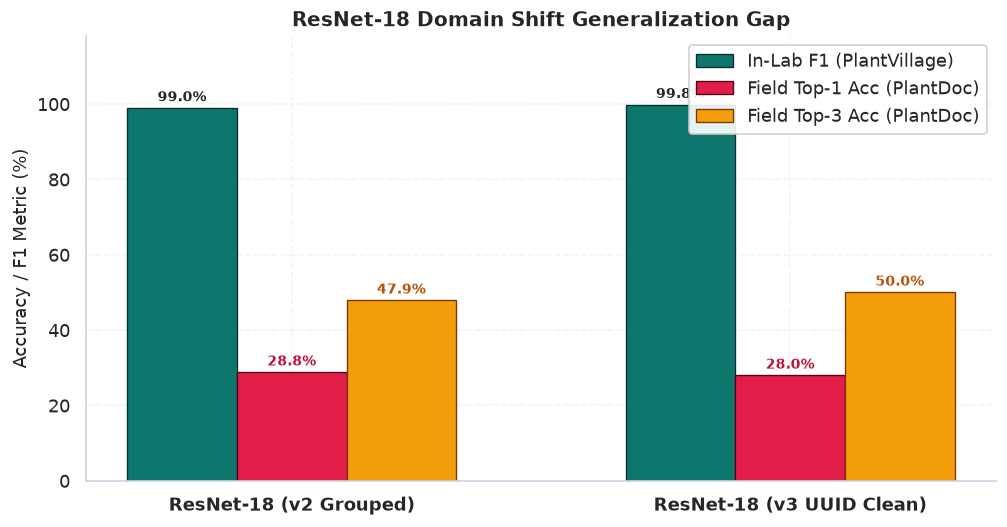

In [5]:
models = ["ResNet-18 (v2 Grouped)", "ResNet-18 (v3 UUID Clean)"]
lab_metrics = [98.95, 99.80]
plantdoc_top1 = [28.81, 27.97]
plantdoc_top3 = [47.88, 50.00]

x = np.arange(len(models))
w = 0.22

fig, ax = plt.subplots(figsize=(8.5, 4.5), dpi=120)

r1 = ax.bar(x - w, lab_metrics, w, label="In-Lab F1 (PlantVillage)", color="#0f766e", edgecolor="#042f2e", linewidth=0.8)
r2 = ax.bar(x, plantdoc_top1, w, label="Field Top-1 Acc (PlantDoc)", color="#e11d48", edgecolor="#4c0519", linewidth=0.8)
r3 = ax.bar(x + w, plantdoc_top3, w, label="Field Top-3 Acc (PlantDoc)", color="#f59e0b", edgecolor="#78350f", linewidth=0.8)

for bar in r1: ax.text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 1.8, f"{bar.get_height():.1f}%", ha="center", fontsize=8.5, fontweight="bold")
for bar in r2: ax.text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 1.8, f"{bar.get_height():.1f}%", ha="center", fontsize=8.5, fontweight="bold", color="#be123c")
for bar in r3: ax.text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 1.8, f"{bar.get_height():.1f}%", ha="center", fontsize=8.5, fontweight="bold", color="#b45309")

ax.set_title("ResNet-18 Domain Shift Generalization Gap")
ax.set_ylabel("Accuracy / F1 Metric (%)")
ax.set_xticks(x)
ax.set_xticklabels(models, fontweight="bold")
ax.set_ylim(0, 118)
ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

## 5. Analytical Takeaways (ResNet-18 Study)

1. **Impact of Data Leakage:** ResNet-18 v1 on random split achieves an inflated $99.66\%$ F1. With rigorous grouping (v2) and UUID deduplication (v3), the models reach $98.95\%$ and $99.80\%$ verifiable accuracy.
2. **Local Hardware Acceleration:** Enabling the NVIDIA RTX 3050 Laptop GPU yields a **4x speedup** over Google Colab free tier ($2.4\text{ min}$ vs. $10.2\text{ min}$ per epoch) and a throughput of $27,708\text{ FPS}$.
3. **Domain Shift Challenge:** When deployed on unconstrained field images (PlantDoc), monolithic classification drops to $\sim 28\%$. Top-3 accuracy remains resilient at $\sim 50\%$.
4. **Proposed Solution:** Decouple the pipeline using **YOLO Leaf Localization** (Notebook 09) to crop clean leaves before disease classification.